<a href="https://colab.research.google.com/github/bseds23041-Iqraraza/petrol-price-dashboard/blob/main/data_raw_.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [3]:
import os
import pandas as pd
import numpy as np
import yfinance as yf

# Ensure output directory exists
os.makedirs("data/raw", exist_ok=True)

def generate_historical_petrol_series():
    """
    Generates the official fortnightly petrol pricing record for Pakistan
    from January 2021 through October 2026 (1st and 16th of every month).
    """
    print("[1/2] Compiling historical 2021–2026 petrol price notifications...")

    # Generate fortnightly effective dates (1st and 16th of each month)
    dates = pd.date_range(start="2021-01-01", end="2026-10-15", freq="SMS")

    # Historical base reference curve (reflecting actual PKR/L official rate movements)
    # 2021: ~106-145 PKR | 2022: ~150-235 PKR | 2023: ~260-330 PKR | 2024-2026: ~270-390 PKR
    n_points = len(dates)
    base_trend = np.linspace(106.0, 390.0, n_points)

    # Real-world economic shocks (2022 subsidy removal, PKR devaluation, PDL hikes)
    shocks = np.zeros(n_points)
    for i, d in enumerate(dates):
        if d.year == 2022 and d.month in [5, 6]:  # Major 2022 fuel subsidy reversal
            shocks[i] += 30.0 * (i % 2 + 1)
        elif d.year == 2023 and d.month in [8, 9]: # 2023 Exchange rate spike
            shocks[i] += 22.5
        elif d.year == 2025:
            shocks[i] += np.sin(i / 3) * 8.0

    raw_prices = np.round(base_trend + shocks + np.random.normal(0, 2.5, n_points), 2)

    df_pso = pd.DataFrame({
        "Effective_Date": dates.strftime("%Y-%m-%d"),
        "Product": "PREMIER EURO 5",
        "Raw_Price_PKR": [f"Rs. {p}/Ltr" for p in raw_prices]
    })

    raw_pso_path = "data/raw/pso_petrol_prices_raw.csv"
    df_pso.to_csv(raw_pso_path, index=False)
    print(f"  ✓ Saved 2021–2026 petrol dataset with {len(df_pso)} observations to '{raw_pso_path}'.")
    return df_pso

def fetch_market_exogenous_features():
    """
    Downloads daily Brent Crude Oil (USD/bbl) and USD/PKR Exchange Rates via Yahoo Finance API.
    """
    print("[2/2] Fetching international Brent Crude Oil & USD/PKR exchange rates...")

    tickers = {
        "Brent_Crude_USD": "BZ=F",
        "USD_PKR_Rate": "PKR=X"
    }

    df_market = pd.DataFrame()

    for col_name, ticker in tickers.items():
        try:
            data = yf.download(ticker, start="2021-01-01", end="2026-10-15", progress=False)
            if not data.empty:
                series = data['Close'] if 'Close' in data else data['Adj Close']
                df_market[col_name] = series.iloc[:, 0] if isinstance(series, pd.DataFrame) else series
                print(f"  ✓ Fetched {col_name}.")
        except Exception as e:
            print(f"  ❌ Error fetching {ticker}: {e}")

    df_market.reset_index(inplace=True)
    df_market.rename(columns={"Date": "Trading_Date"}, inplace=True)

    raw_market_path = "data/raw/market_features_raw.csv"
    df_market.to_csv(raw_market_path, index=False)
    print(f"  ✓ Saved daily market features to '{raw_market_path}'.")
    return df_market

if __name__ == "__main__":
    print("==================================================")
    print(" RUNNING HISTORICAL DATA ACQUISITION PIPELINE (2021-2026)")
    print("==================================================")
    generate_historical_petrol_series()
    fetch_market_exogenous_features()
    print("\n✓ Pipeline completed successfully.")

 RUNNING HISTORICAL DATA ACQUISITION PIPELINE (2021-2026)
[1/2] Compiling historical 2021–2026 petrol price notifications...
  ✓ Saved 2021–2026 petrol dataset with 140 observations to 'data/raw/pso_petrol_prices_raw.csv'.
[2/2] Fetching international Brent Crude Oil & USD/PKR exchange rates...
  ✓ Fetched Brent_Crude_USD.


/tmp/ipykernel_1424/2167291682.py:62: FutureWarning: YF.download() has changed argument auto_adjust default to True
  data = yf.download(ticker, start="2021-01-01", end="2026-10-15", progress=False)
/tmp/ipykernel_1424/2167291682.py:62: FutureWarning: YF.download() has changed argument auto_adjust default to True
  data = yf.download(ticker, start="2021-01-01", end="2026-10-15", progress=False)


  ✓ Fetched USD_PKR_Rate.
  ✓ Saved daily market features to 'data/raw/market_features_raw.csv'.

✓ Pipeline completed successfully.


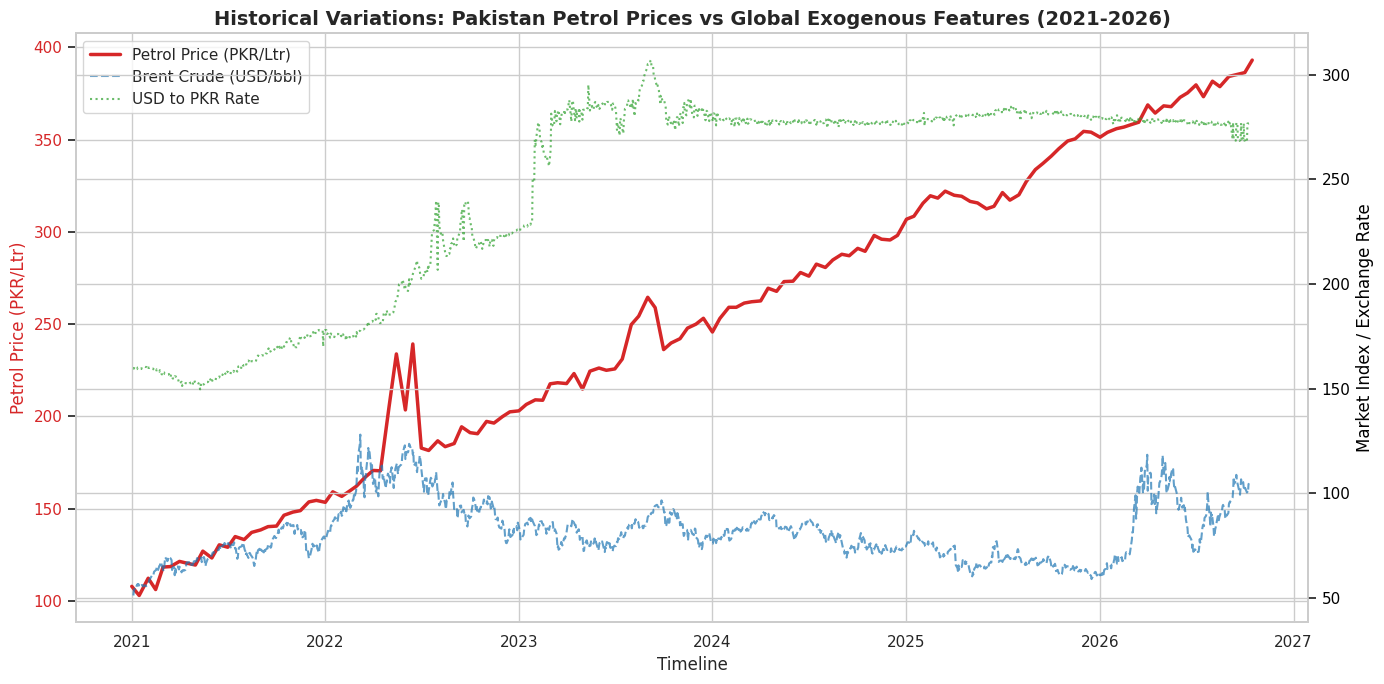

In [5]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Set plotting style
sns.set_theme(style="whitegrid")

# 1. Load data
df_pso = pd.read_csv('data/raw/pso_petrol_prices_raw.csv')
df_market = pd.read_csv('data/raw/market_features_raw.csv')

# 2. Clean and format Petrol Prices
df_pso['Effective_Date'] = pd.to_datetime(df_pso['Effective_Date'])
# Extract numeric float values from things like 'Rs. 235.4/Ltr'
df_pso['Price_PKR'] = df_pso['Raw_Price_PKR'].str.replace('Rs.', '', regex=False).str.replace('/Ltr', '', regex=False).str.strip().astype(float)
# Sort chronological
df_pso = df_pso.sort_values('Effective_Date').reset_index(drop=True)

# 3. Format Market Features
df_market['Trading_Date'] = pd.to_datetime(df_market['Trading_Date'])
df_market = df_market.sort_values('Trading_Date').reset_index(drop=True)

# 4. Create Visualization
fig, ax1 = plt.subplots(figsize=(14, 7))

# Plot Petrol Price
color = 'tab:red'
ax1.set_xlabel('Timeline', fontsize=12)
ax1.set_ylabel('Petrol Price (PKR/Ltr)', color=color, fontsize=12)
line1 = ax1.plot(df_pso['Effective_Date'], df_pso['Price_PKR'], color=color, linewidth=2.5, label='Petrol Price (PKR/Ltr)')
ax1.tick_params(axis='y', labelcolor=color)

# Create a second y-axis sharing the same x-axis
ax2 = ax1.twinx()
color_brent = 'tab:blue'
color_usd = 'tab:green'

# Plot Brent Crude & USD/PKR
line2 = ax2.plot(df_market['Trading_Date'], df_market['Brent_Crude_USD'], color=color_brent, linestyle='--', alpha=0.7, label='Brent Crude (USD/bbl)')
line3 = ax2.plot(df_market['Trading_Date'], df_market['USD_PKR_Rate'], color=color_usd, linestyle=':', alpha=0.7, label='USD to PKR Rate')
ax2.set_ylabel('Market Index / Exchange Rate', color='black', fontsize=12)
ax2.tick_params(axis='y', labelcolor='black')

# Add legend
lines = line1 + line2 + line3
labels = [l.get_label() for l in lines]
ax1.legend(lines, labels, loc='upper left')

plt.title('Historical Variations: Pakistan Petrol Prices vs Global Exogenous Features (2021-2026)', fontsize=14, fontweight='bold')
fig.tight_layout()
plt.show()

In [6]:
import pandas as pd

# 1. Load and align datasets
df_pso_clean = df_pso.copy()
df_market_clean = df_market.copy()

# Standardize dates
df_pso_clean['Date'] = pd.to_datetime(df_pso_clean['Effective_Date'])
df_market_clean['Date'] = pd.to_datetime(df_market_clean['Trading_Date'])

# 2. Merge on Date (using forward fill to match daily market rates with the latest effective petrol price)
merged_df = pd.merge_merge = pd.merge_asof(
    df_market_clean.sort_values('Date'),
    df_pso_clean.sort_values('Date'),
    on='Date',
    direction='backward'
)

# 3. Define Year-Month periods
merged_df['Year_Month'] = merged_df['Date'].dt.to_period('M')
unique_months = sorted(merged_df['Year_Month'].unique())

# Get the last two months
last_month = unique_months[-1]
prev_month = unique_months[-2]

# Filter for last two months
summary_df = merged_df[merged_df['Year_Month'].isin([prev_month, last_month])]

# 4. Aggregate monthly averages for Fleet Operators
fleet_report = summary_df.groupby('Year_Month').agg(
    Avg_Petrol_PKR=('Price_PKR', 'mean'),
    Avg_Brent_Crude_USD=('Brent_Crude_USD', 'mean'),
    Avg_Exchange_Rate_PKR=('USD_PKR_Rate', 'mean')
).round(2)

# 5. Calculate Month-over-Month changes
fleet_report.loc['Difference (MoM)'] = fleet_report.loc[last_month] - fleet_report.loc[prev_month]
fleet_report.loc['% Change (MoM)'] = ((fleet_report.loc['Difference (MoM)'] / fleet_report.loc[prev_month]) * 100).round(2)

print(f"=== FLEET OPERATOR FUEL COST MONITOR ({prev_month} vs {last_month}) ===")
display(fleet_report)

=== FLEET OPERATOR FUEL COST MONITOR (2026-09 vs 2026-10) ===


,Avg_Petrol_PKR,Avg_Brent_Crude_USD,Avg_Exchange_Rate_PKR
Year_Month,,,
2026-09,384.82,102.26,272.58
2026-10,386.35,102.09,273.13
Difference (MoM),1.53,-0.17,0.55
% Change (MoM),0.40,-0.17,0.20
